# Phyloseq-working

## 10.17.26 | tidy metadata

### Setting up R/phyloseq with conda environment in unity

Add phyloseq to `dada2-env` in terminal
```
conda activate dada2-env
conda install -c bionconda bioconda-phyloseq
```

### Metadata tidying

In [ ]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(Biostrings)
    library(tidyverse)
})

In [ ]:
# Read 16S processing tracker csv
meta16S <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/16S_tracker.csv")
dim(meta16S)
head(meta16S)

In [ ]:
# Tidy data
meta16S <- meta16S %>% 
                mutate(Original_order = NULL) %>%
                # Un-concatenate sample name
                separate(Sample_name,  into = c("Year", "Phase_1_treat", "Phase_2_treat", "Tag"), sep = "_", remove = FALSE) %>%
                # Add tissue type to sample name to match ASV table
                mutate(Sample_name = paste0(Sample_name, sep = "_", Tissue)) %>%
                # Separate the treatment and replicate into two columns
                extract(Phase_1_treat, into = c("Phase_1_treat", "Phase_1_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
                extract(Phase_2_treat, into = c("Phase_2_treat", "Phase_2_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
                # Add column for treatment combination
                mutate(Combined_treat = paste0(Phase_1_treat, Phase_2_treat)) %>%
                mutate(Combined_treat = gsub("[^A-Z]", "", Combined_treat)) %>%
                relocate(Combined_treat, .after = Year) %>%
                # Make the treatment replicate an integer rather than a string
                mutate(Phase_1_rep = as.integer(Phase_1_rep)) %>%
                mutate(Phase_2_rep = as.integer(Phase_2_rep)) %>%
                # Rename some columns
                rename(Date = X16S_date) %>%
                rename(Adapters = X16S_adapters) %>%
                # Format dates
                mutate(Date = as.Date(Date, format = "%m/%d/%y")) %>%
                mutate(Index_date = as.Date(Index_date, format = "%m/%d/%y"))
head(meta16S)

In [ ]:
# Check warning message
meta16S[239:247,]
meta16S[280:283,]
# Missing pieces are control samples

In [ ]:
# Remove empty rows 282, 283
meta16S <- meta16S[-282:-283,]
tail(meta16S)

In [ ]:
# Save tided csv
write.csv(meta16S, "/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=FALSE)

## 10.18.26 | phyloseq object using decipher taxonomy

In [2]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(Biostrings)
    library(tidyverse)
})

In [3]:
# Read ASV table
asvTable <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim_2.rds")

# Read taxonomy table
taxaDecipher <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/decipher_taxa_sp.rds")

# Read tidied metadata
sampleMetadata <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=1)

In [3]:
# Check that row names are identical
head(asvTable)
head(sampleMetadata)

,GAAGGGGGCGAGCGTTGTTCGGAATTACTGGGCGTAAAGGGCGTCTAGGTGGTTTTGTTAGTTGGATGTGAAAGCCCTCGGCTCAACCGAGGAATTGCATCCAAAACTGCATTACTAGAGTGTGAAAGGGGAAGGCGGAATTCCAAGTGTAGCGGTGAAATGCGTAGATATTTGGAGGAACACCGGTGGCGAAGGCGGCCTTCTGGTTCAACACTGACACTAAAGCGCGAAGGCTAGGGGAGCGAAC,GAAGGGGGCAAGCGTTGTTCGGAATTACTGGGCGTAAAGAGTACGTAGGCGGTTAGATTAGTTAGGTGTGAAATCCCGGAGCTCAACTTCGGAGTTGCACTTAATACTGTTTAACTAGAATTCAAGAGGGGAGAGTGGAATTTCCAGTGTAGGGGTGATATCCGTAGATATTGGAAGGAACATCAGAGGCGAAGGCGACTCTCTGGCTTGACATTGACGCTGAGGTACGAAAGCGTGGGTAGCAAAC,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTTGTAAGTCTGTTGTTAAAGCGTGGAGCTTAACTCCATTTCAGCAATGGAAACTGTAAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGAGGCTCAACTTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAAT,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTGTCAAGTCTGCTGTTAAAGCGTGGAGCTTAACTCCATTTCGGCAGTGGAAACTGACAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGGGGCGAGCGTTATTCGGAATTATTGGGTGTAAAGTGTGCGTAGGCGGCTTAGTAAGTTAATGGTGAAATCCCGGGGCTCAACCCCGGGGCTGCTTTTAGAACTGCTAAGCTGGAGTTGGAAAGAGGATAGCAGAATTCCTAGTGTAGAGGTGAAATTCGTAGATATTAGGAGGAATACCGGAGGCGAAGGCGGCTGTCTGGTTCCATACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GGAGGGTGCAAGCGTTACTCGGAATTACTGGGCGTAAAGGGTGCGTAGGCGTCTTATTAAGTCAGATGTGAAATCCTGTGGCTCAACCATAGAACTGCATTTGAAACTGGTAAGATAGAGTTCAGAAGGGGCAAGTGGAATTAGTGGTGTAGGGGTAAAATCCGTAGATATCACTAGGAATACCAAAAGCGAAGGCGACTTGCTAGGATGACACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GTAGGTCCCAAGCGTTATCCGGAATTATTGGGCGTAAAGGGTCCGTAGACGGTTTATTAAGTCTGATGTGAAAGCCACCGGCTCAACCGGTGAAACGCATTAGATACTGGTAAACTAGAGTATGTTAGAGGATAGTGGAATTCCATGTGTAGCGGTGAAATGCGTAGATATATGGAGGAACACCAGTGGCGAAGGCGGCTATCTGGGACATTACTGACGTTGAGGGACGAAAGCGTGGGGAGCGAAC,GAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGATGGCTCAACCTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAA,AACCAAGCGAACGTTATTCGGAATTACTGGGCTTAAAGCGCGTGTAGGCGGATTGCCACGTCGGCTGTTGAAATCCCCCGGCTCAACCGGGGAACAGGCACCGATACGAGTGATCTTGAGGTGGGTAGGGGAGACTGGAACTTCCGGTGGAGCGGTGAAATGCGTTGAGATCGGAAGGAACGCCCGCGGCGAAAGCGAGTCTCTGGCCCCATACTGACGCTGAGACGCGAAAGCCAGGGGAGCAAA,⋯,ATCTTACGGATGGCATGACAGTAAGAGAATTATGCAGTGCTGCCATAACCATGAGTGATAACACTGCGGCCAACTTACTTCTGACAACGATCGGAGGACCGAAGGAGCTAACCGCTTTTTTGCACAACATGGGGGATCATGTAACTCGCCTTGATCGTTGGGAACCGGAGCTGAATGAAGCCATACCAAACGACGAGCGTGACACCACGATGCCTGTAGCAATGGCAACAACGTTGCGCAAA,GGTCGTTCGGCTGCGGCGAGCGGTATCAGCTCACTCAAAGGCGGTAATACGGTTATCCACAGAATCAGGGGATAACGCAGGAAAGAACATGTGAGCAAAAGGCCAGCAAAAGGCCAGGAACCGTAAAAAGGCCGCGTTGCTGGCGTTTTTCCATAGGCTCCGCCCCCCTGACGAGCATCACAAAAATCGACGCTCAAGTCAGAGGTGGCGAAACCCGACAGGACTATAAAGATACCAGGCGTTTCCCCCTGGAAGCTCCCTCGTGCGCTCTCC,CTCATCATTGGAAAACGTTCTTCGGGGCGAAAACTCTCAAGGATCTTACCGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAA,AAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAAAAATAAACAAATAGGGGTTCCGCGCACATTTCCCCGAAAAGTGCCACCTGACGTCTAAGAAACCATTATTATCATGACATTAACCTATAAAAATAGGCGTATCACGAGGCCCTTTCGTCTCGCGCGTTTCGGTGATGACGGT,CCAGATTTATCAGCAATAAACCAGCCAGCCGGAAGGGCCGAGCGCAGAAGTGGTCCTGCAACTTTATCCGCCTCCATCCAGTCTATTAATTGTTGCCGGGAAGCTAGAGTAAGTAGTTCGCCAGTTAATAGTTTGCGCAACGTTGTTGCCATTGCTACAGGCATCGTGGTGTCACGCTCGTCGTTTGGTATGGCTTCATTCAGCTCCGGTTCCCAACGATCAAGGCGAGTTACATGATCCCCCATGTT,CGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGT

,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,Phase,Tissue,Concentration,⋯,Pooled_notes,Index_primers,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<int>,<chr>,<dbl>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
2024_Both05_Warm03_O33_gut,2024,BW,Both,5,Warm,3,O33,2,gut,53.0,⋯,<15uL,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.10,4.10,
2024_Both06_Hyp06_O72_gut,2024,BH,Both,6,Hyp,6,O72,2,gut,53.8,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,8.88,2.82,
2024_Cont02_Warm02_W15_gut,2024,CW,Cont,2,Warm,2,W15,2,gut,29.2,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.64,3.77,
2024_Both03_Warm01_O6_gut,2024,BW,Both,3,Warm,1,O6,2,gut,77.8,⋯,<15uL,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,10.00,2.50,
2024_Both03_Warm04_O41_gut,2024,BW,Both,3,Warm,4,O41,2,gut,86.9,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,9.86,2.54,
2024_Both04_Warm02_O19_gut,2024,BW,Both,4,Warm,2,O19,2,gut,38.7,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,7.52,3.32,


In [4]:
# Rearrange metadata sample order to match ASV table sample order
sampleMetadata <- sampleMetadata[match(rownames(asvTable), rownames(sampleMetadata)), ]
head(asvTable)
head(sampleMetadata)

,GAAGGGGGCGAGCGTTGTTCGGAATTACTGGGCGTAAAGGGCGTCTAGGTGGTTTTGTTAGTTGGATGTGAAAGCCCTCGGCTCAACCGAGGAATTGCATCCAAAACTGCATTACTAGAGTGTGAAAGGGGAAGGCGGAATTCCAAGTGTAGCGGTGAAATGCGTAGATATTTGGAGGAACACCGGTGGCGAAGGCGGCCTTCTGGTTCAACACTGACACTAAAGCGCGAAGGCTAGGGGAGCGAAC,GAAGGGGGCAAGCGTTGTTCGGAATTACTGGGCGTAAAGAGTACGTAGGCGGTTAGATTAGTTAGGTGTGAAATCCCGGAGCTCAACTTCGGAGTTGCACTTAATACTGTTTAACTAGAATTCAAGAGGGGAGAGTGGAATTTCCAGTGTAGGGGTGATATCCGTAGATATTGGAAGGAACATCAGAGGCGAAGGCGACTCTCTGGCTTGACATTGACGCTGAGGTACGAAAGCGTGGGTAGCAAAC,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTTGTAAGTCTGTTGTTAAAGCGTGGAGCTTAACTCCATTTCAGCAATGGAAACTGTAAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGAGGCTCAACTTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAAT,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTGTCAAGTCTGCTGTTAAAGCGTGGAGCTTAACTCCATTTCGGCAGTGGAAACTGACAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGGGGCGAGCGTTATTCGGAATTATTGGGTGTAAAGTGTGCGTAGGCGGCTTAGTAAGTTAATGGTGAAATCCCGGGGCTCAACCCCGGGGCTGCTTTTAGAACTGCTAAGCTGGAGTTGGAAAGAGGATAGCAGAATTCCTAGTGTAGAGGTGAAATTCGTAGATATTAGGAGGAATACCGGAGGCGAAGGCGGCTGTCTGGTTCCATACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GGAGGGTGCAAGCGTTACTCGGAATTACTGGGCGTAAAGGGTGCGTAGGCGTCTTATTAAGTCAGATGTGAAATCCTGTGGCTCAACCATAGAACTGCATTTGAAACTGGTAAGATAGAGTTCAGAAGGGGCAAGTGGAATTAGTGGTGTAGGGGTAAAATCCGTAGATATCACTAGGAATACCAAAAGCGAAGGCGACTTGCTAGGATGACACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GTAGGTCCCAAGCGTTATCCGGAATTATTGGGCGTAAAGGGTCCGTAGACGGTTTATTAAGTCTGATGTGAAAGCCACCGGCTCAACCGGTGAAACGCATTAGATACTGGTAAACTAGAGTATGTTAGAGGATAGTGGAATTCCATGTGTAGCGGTGAAATGCGTAGATATATGGAGGAACACCAGTGGCGAAGGCGGCTATCTGGGACATTACTGACGTTGAGGGACGAAAGCGTGGGGAGCGAAC,GAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGATGGCTCAACCTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAA,AACCAAGCGAACGTTATTCGGAATTACTGGGCTTAAAGCGCGTGTAGGCGGATTGCCACGTCGGCTGTTGAAATCCCCCGGCTCAACCGGGGAACAGGCACCGATACGAGTGATCTTGAGGTGGGTAGGGGAGACTGGAACTTCCGGTGGAGCGGTGAAATGCGTTGAGATCGGAAGGAACGCCCGCGGCGAAAGCGAGTCTCTGGCCCCATACTGACGCTGAGACGCGAAAGCCAGGGGAGCAAA,⋯,ATCTTACGGATGGCATGACAGTAAGAGAATTATGCAGTGCTGCCATAACCATGAGTGATAACACTGCGGCCAACTTACTTCTGACAACGATCGGAGGACCGAAGGAGCTAACCGCTTTTTTGCACAACATGGGGGATCATGTAACTCGCCTTGATCGTTGGGAACCGGAGCTGAATGAAGCCATACCAAACGACGAGCGTGACACCACGATGCCTGTAGCAATGGCAACAACGTTGCGCAAA,GGTCGTTCGGCTGCGGCGAGCGGTATCAGCTCACTCAAAGGCGGTAATACGGTTATCCACAGAATCAGGGGATAACGCAGGAAAGAACATGTGAGCAAAAGGCCAGCAAAAGGCCAGGAACCGTAAAAAGGCCGCGTTGCTGGCGTTTTTCCATAGGCTCCGCCCCCCTGACGAGCATCACAAAAATCGACGCTCAAGTCAGAGGTGGCGAAACCCGACAGGACTATAAAGATACCAGGCGTTTCCCCCTGGAAGCTCCCTCGTGCGCTCTCC,CTCATCATTGGAAAACGTTCTTCGGGGCGAAAACTCTCAAGGATCTTACCGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAA,AAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAAAAATAAACAAATAGGGGTTCCGCGCACATTTCCCCGAAAAGTGCCACCTGACGTCTAAGAAACCATTATTATCATGACATTAACCTATAAAAATAGGCGTATCACGAGGCCCTTTCGTCTCGCGCGTTTCGGTGATGACGGT,CCAGATTTATCAGCAATAAACCAGCCAGCCGGAAGGGCCGAGCGCAGAAGTGGTCCTGCAACTTTATCCGCCTCCATCCAGTCTATTAATTGTTGCCGGGAAGCTAGAGTAAGTAGTTCGCCAGTTAATAGTTTGCGCAACGTTGTTGCCATTGCTACAGGCATCGTGGTGTCACGCTCGTCGTTTGGTATGGCTTCATTCAGCTCCGGTTCCCAACGATCAAGGCGAGTTACATGATCCCCCATGTT,CGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGT

,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,Phase,Tissue,Concentration,⋯,Pooled_notes,Index_primers,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<int>,<chr>,<dbl>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
2024_Both01_Both01_O1_gill,2024,BB,Both,1,Both,1,O1,2,gill,18.100,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.66,3.75,
2024_Both01_Both01_O1_gut,2024,BB,Both,1,Both,1,O1,2,gut,43.000,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,8.24,3.03,
2024_Both01_Null_O03_gill,2024,BNA,Both,1,NA,NA,O03,1,gill,0.980,⋯,,BFi-13,2026-07-08,3,7/10/26,,7/22/26,4.98,5.02,
2024_Both01_Null_O03_gut,2024,BNA,Both,1,NA,NA,O03,1,gut,0.886,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,5.80,4.31,Diluted final sample 1:3
2024_Both01_Warm05_O50_gill,2024,BW,Both,1,Warm,5,O50,2,gill,75.200,⋯,,BFi-13,2026-07-06,1,7/6/26,NA,NA,10.07,2.48,Diluted final sample 1:3
2024_Both01_Warm05_O50_gut,2024,BW,Both,1,Warm,5,O50,2,gut,46.900,⋯,,BFi-15,2026-07-03,2,7/3/26,NA,NA,7.40,3.38,Diluted final sample 1:3


In [9]:
# Create phyloseq object
ps <- phyloseq(otu_table(asvTable, taxa_are_rows = FALSE),
                     sample_data(sampleMetadata),
                     tax_table(taxaDecipher))
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]

In [10]:
# Extract ASV sequences
dna <- Biostrings::DNAStringSet(taxa_names(ps))
names(dna) <- taxa_names(ps)

# Create reference sequence component of phyloseq object to store the raw ASVs
ps <- merge_phyloseq(ps, dna)

# Rename ASVs numerically
taxa_names(ps) <- paste0("ASV", seq(ntaxa(ps)))
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

In [11]:
# Save phyloseq object
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps.rds")

## 10.20.26 | clean phyloseq object

Continue work with the phyloseq object created 10.18.26 using the decipher taxonomic assignment tool.

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(Biostrings)
    library(tidyverse)
})

In [2]:
# Read in phyloseq object
ps <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps.rds")

### Check ASV prevalence

In [5]:
# Look at prevalence and total abundance of each ASV
ASVprev <- apply(X = otu_table(ps),
                 MARGIN = ifelse(taxa_are_rows(ps), yes = 1, no = 2),
                 FUN = function(x){sum(x > 0)})
ASVprev <- data.frame(Prevalence = ASVprev,
                      TotalAbundance = taxa_sums(ps),
                      tax_table(ps))

head(ASVprev)

,Prevalence,TotalAbundance,domain,phylum,class,order,family,genus,species
,<int>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ASV1,277,7213455,Bacteria,NA,NA,NA,NA,NA,NA
ASV2,280,6422050,NA,NA,NA,NA,NA,NA,NA
ASV3,280,6190359,Bacteria,Cyanobacteriota,Cyanobacteriia,Synechococcales,Cyanobiaceae,Cyanobium PCC-6307,NA
ASV4,275,4900509,Bacteria,Cyanobacteriota,Cyanobacteriia,Chloroplast,Incertae Sedis_227,Incertae Sedis_497,NA
ASV5,279,4544204,Bacteria,Cyanobacteriota,Cyanobacteriia,Synechococcales,Cyanobiaceae,Cyanobium PCC-6307,NA
ASV6,249,2869369,NA,NA,NA,NA,NA,NA,NA


### Prune samples and transform reads to relative abundance

**Cleaned and pruned phyloseq object to use going forward will be ps_norm**

In [96]:
# Remove samples with less than 10k reads
ps_10k <- prune_samples(sample_sums(ps) >= 10000, ps)

# Compare phyloseq objects
ps
ps_10k

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

In [97]:
# Explore which samples were lost
low_samples <- sample_sums(ps) < 10000
sample_names(ps)[low_samples]

[1] "2024_Both01_Null_O03_gill"   "2024_Both04_Null_O32_gill"  
[3] "2024_Both05_Both06_O69_gill" "2024_Cont03_Null_W21_gill"  
[5] "2024_Cont04_Cont06_W67_gill" "2024_Warm01_Hyp05_G49_gill" 
[7] "Pooled_negative_rack3_2_NA"

**Samples removed due to <10,000 reads**  
Phase 1 - B1O3_gill, B4O32_gill, C3W21_gill  
Phase 2 - B5B6O69_gill, C4C6W67_gill, W1J5G49_gill  
Negative - Pooled negative rack 3_2

In [98]:
# Keep just bacteria
ps_bacteria <- subset_taxa(ps_10k, domain == "Bacteria")
ps_bacteria

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66795 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66795 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66795 reference sequences ]

In [99]:
# Remove chloroplasts
ps_noChloroplast <- subset_taxa(ps_bacteria, order != "Chloroplast")
ps_noChloroplast

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 39515 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 39515 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 39515 reference sequences ]

In [100]:
# Remove mitochondria
ps_noMitochondria <- subset_taxa(ps_noChloroplast, family != "Mitochondra")
ps_noMitochondria

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 34809 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 34809 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 34809 reference sequences ]

In [101]:
# Remove taxa that are no longer represented in phyloseq object
ps_prune <- prune_taxa(taxa_sums(ps_noMitochondria) > 0, ps_noMitochondria)
ps_prune

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 34583 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 34583 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 34583 reference sequences ]

In [102]:
# Convert raw counts to relative abundances
ps_norm = transform_sample_counts(ps_prune, function(x) 1E6 * x / sum(x))
ps_norm

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 34583 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 34583 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 34583 reference sequences ]

In [3]:
# Save phyloseq object
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps_norm.rds")

### Subsets of phyloseq object ps_norm

Phase 1 - Cont v. Warm v. Hyp vs. Both
- Gill v. gut tissue

Phase 2 - Priming effects
- Both treatment (CC, CB, BC, BB)
- Warm treatment (CC, CW, WC, WW)
- Hypoxic treatment (CC, CH, HC, HH)
- Gill v. gut tissue

Phase 2 - Less direct carryover effects
- P1 = both, P2 = single stressor (BC, BW, BW, BH)
- Gill v. gut tissue

In [5]:
# Subset samples to copy 2018 nmds variables
ps_hyp <- subset_samples(ps, Tissue == "gill" & Phase_2_treat %in% c("Hyp", "Both"))
ps_hyp <- prune_taxa(taxa_sums(ps_hyp) > 0, ps_hyp)
ps_hyp
with(sample_data(ps_hyp), table(Phase, Combined_treat))

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 13806 taxa and 49 samples ]
sample_data() Sample Data:       [ 49 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 13806 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 13806 reference sequences ]

     Combined_treat
Phase BB BH CB CH HB HH WB WH
    2  6  6  6  6  6  6  7  6

**Why does warm both have 7 samples?**

Square root transformation
Wisconsin double standardization
Run 0 stress 0.1837046 
Run 1 stress 0.185374 
Run 2 stress 0.1958718 
Run 3 stress 0.2129863 
Run 4 stress 0.1675417 
... New best solution
... Procrustes: rmse 0.09098637  max resid 0.4579473 
Run 5 stress 0.1933583 
Run 6 stress 0.1998319 
Run 7 stress 0.1686478 
Run 8 stress 0.1680692 
Run 9 stress 0.1686416 
Run 10 stress 0.1695853 
Run 11 stress 0.1929525 
Run 12 stress 0.1859701 
Run 13 stress 0.1809841 
Run 14 stress 0.20309 
Run 15 stress 0.1996869 
Run 16 stress 0.1771004 
Run 17 stress 0.1958759 
Run 18 stress 0.2108643 
Run 19 stress 0.2001384 
Run 20 stress 0.1836617 
*** Best solution was not repeated -- monoMDS stopping criteria:
    20: stress ratio > sratmax


Warning message in postMDS(out$points, dis, plot = max(0, plot - 1), ...):
“skipping half-change scaling: too few points below threshold”
Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the phyloseq package.
  Please report the issue at <https://github.com/joey711/phyloseq/issues>.”


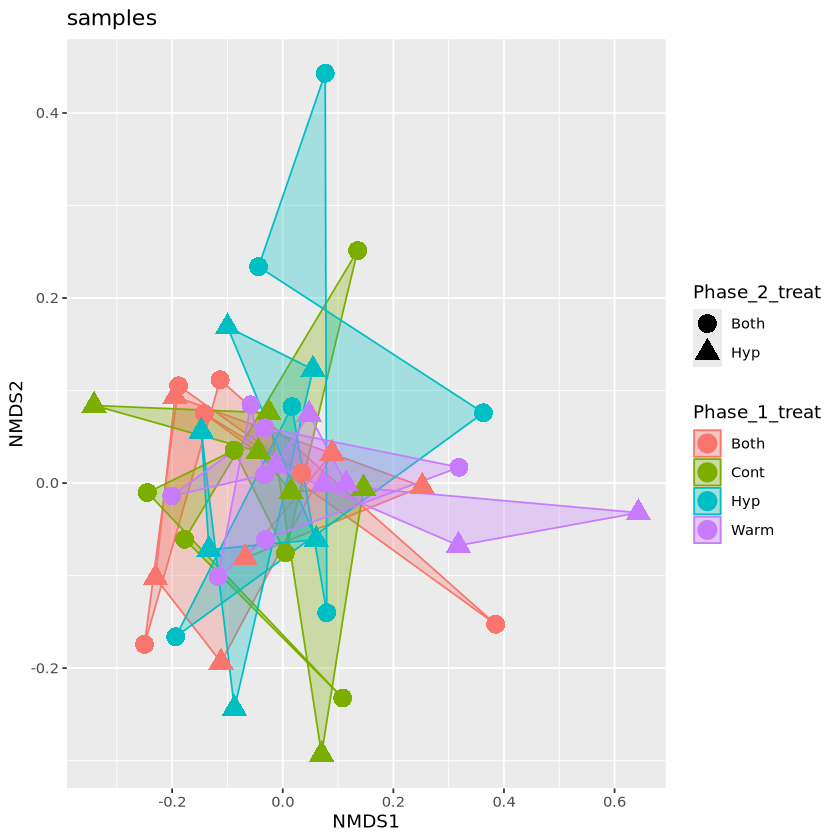

In [6]:
# nmds with hypoxic and both samples
hyp.ord <- ordinate(ps_hyp, "NMDS", "bray")
p2 = plot_ordination(ps_hyp, hyp.ord, type="samples", color="Phase_1_treat", shape="Phase_2_treat") 
p2 + geom_polygon(aes(fill=Phase_1_treat), alpha=0.3) + geom_point(size=5) + ggtitle("samples")

In [112]:
# Subset samples
ps_hyp2 <- subset_samples(ps_norm, Phase == "2" & Combined_treat %in% c("CC", "CH", "HC", "HH"))
ps_hyp2

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 34583 taxa and 47 samples ]
sample_data() Sample Data:       [ 47 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 34583 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 34583 reference sequences ]

In [113]:
# Remove taxa absent from the subset
ps_hyp2 <- prune_taxa(taxa_sums(ps_hyp2) > 0, ps_hyp2)
ps_hyp2

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 6921 taxa and 47 samples ]
sample_data() Sample Data:       [ 47 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 6921 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 6921 reference sequences ]

In [114]:
with(sample_data(ps_hyp2), table(Phase, Combined_treat))
# C4C6W67_gill lost due to low reads

     Combined_treat
Phase CC CH HC HH
    2 11 12 12 12

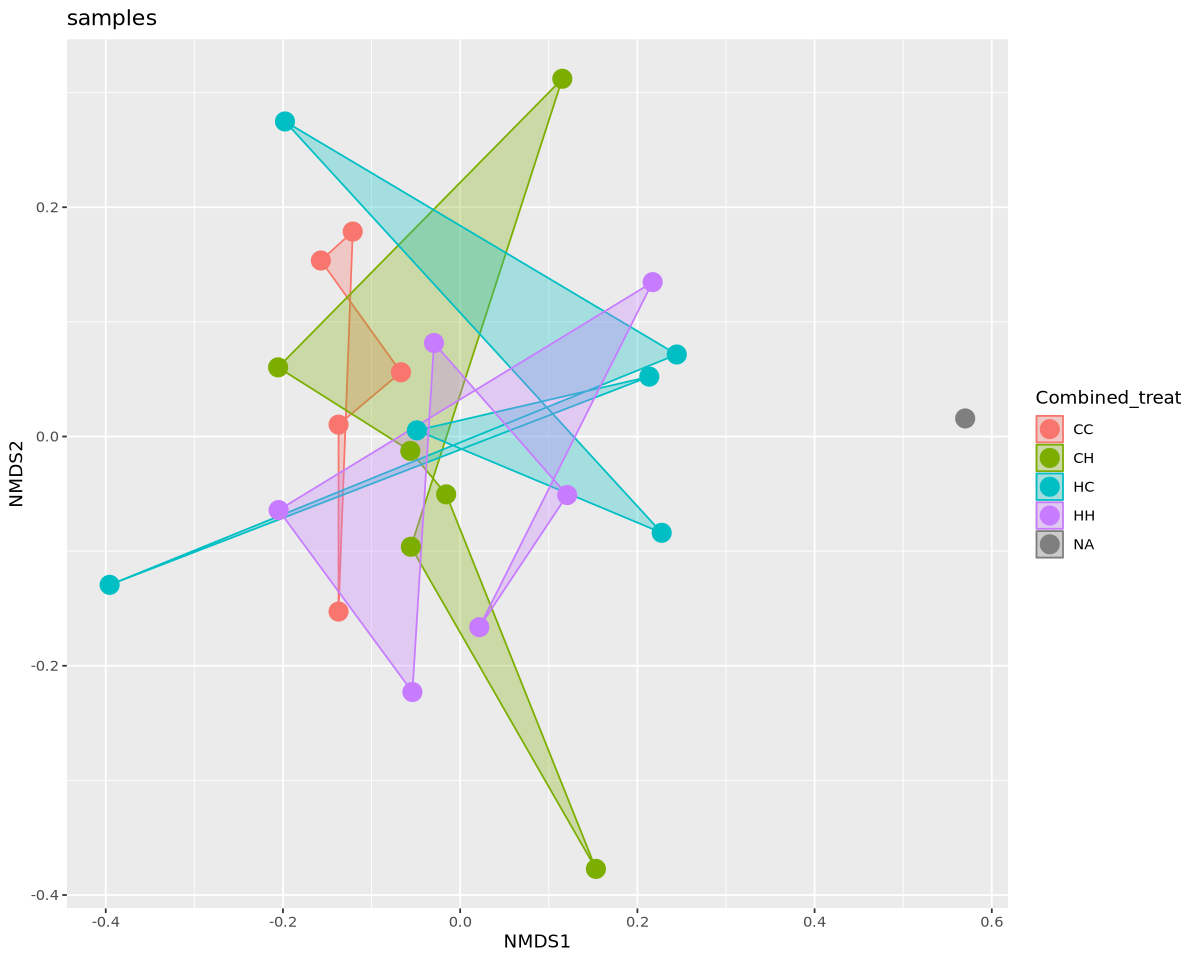

In [119]:
p2 = plot_ordination(ps_hyp2, hyp2.ord, type="samples", color="Combined_treat") 
p2 + geom_polygon(aes(fill=Combined_treat), alpha=0.3) + geom_point(size=5) + ggtitle("samples")

In [155]:
ps_hyp2_gill <- subset_samples(ps_hyp2, Tissue == "gill")


In [159]:
ordu_gill = ordinate(ps_hyp2, "PCoA", "bray")
str(ordu_gill)

List of 5
 $ correction: chr [1:2] "none" "1"
 $ note      : chr "No correction was applied to the negative eigenvalues"
 $ values    :'data.frame':	47 obs. of  6 variables:
  ..$ Eigenvalues   : num [1:47] 2.802 1.243 1.019 0.852 0.591 ...
  ..$ Relative_eig  : num [1:47] 0.2233 0.0991 0.0812 0.0679 0.0471 ...
  ..$ Rel_corr_eig  : num [1:47] 0.2192 0.0975 0.08 0.0669 0.0465 ...
  ..$ Broken_stick  : num [1:47] 0.0977 0.0754 0.0643 0.0569 0.0514 ...
  ..$ Cum_corr_eig  : num [1:47] 0.219 0.317 0.397 0.464 0.51 ...
  ..$ Cumul_br_stick: num [1:47] 0.0977 0.1731 0.2374 0.2944 0.3457 ...
 $ vectors   : num [1:47, 1:45] -0.182 -0.307 0.132 -0.238 0.371 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : chr [1:47] "2024_Cont01_Cont04_W37_gill" "2024_Cont01_Cont04_W37_gut" "2024_Cont01_Hyp02_W13_gill" "2024_Cont01_Hyp02_W13_gut" ...
  .. ..$ : chr [1:45] "Axis.1" "Axis.2" "Axis.3" "Axis.4" ...
 $ trace     : num 12.5
 - attr(*, "class")= chr "pcoa"


In [116]:
ordu = ordinate(ps_hyp2, "PCoA", "bray")
str(ordu)
eig <- ordu$values$Eigenvalues
eig

List of 5
 $ correction: chr [1:2] "none" "1"
 $ note      : chr "No correction was applied to the negative eigenvalues"
 $ values    :'data.frame':	47 obs. of  6 variables:
  ..$ Eigenvalues   : num [1:47] 2.802 1.243 1.019 0.852 0.591 ...
  ..$ Relative_eig  : num [1:47] 0.2233 0.0991 0.0812 0.0679 0.0471 ...
  ..$ Rel_corr_eig  : num [1:47] 0.2192 0.0975 0.08 0.0669 0.0465 ...
  ..$ Broken_stick  : num [1:47] 0.0977 0.0754 0.0643 0.0569 0.0514 ...
  ..$ Cum_corr_eig  : num [1:47] 0.219 0.317 0.397 0.464 0.51 ...
  ..$ Cumul_br_stick: num [1:47] 0.0977 0.1731 0.2374 0.2944 0.3457 ...
 $ vectors   : num [1:47, 1:45] -0.182 -0.307 0.132 -0.238 0.371 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : chr [1:47] "2024_Cont01_Cont04_W37_gill" "2024_Cont01_Cont04_W37_gut" "2024_Cont01_Hyp02_W13_gill" "2024_Cont01_Hyp02_W13_gut" ...
  .. ..$ : chr [1:45] "Axis.1" "Axis.2" "Axis.3" "Axis.4" ...
 $ trace     : num 12.5
 - attr(*, "class")= chr "pcoa"


[1]  2.802346731  1.243315114  1.018835718  0.851944933  0.590500319
 [6]  0.536999340  0.442936778  0.432243850  0.383745874  0.355608438
[11]  0.295325304  0.275892530  0.254749088  0.230728042  0.220855343
[16]  0.212611730  0.187301657  0.180933608  0.157904135  0.153806909
[21]  0.150193511  0.140154482  0.133796874  0.122731535  0.115555711
[26]  0.104574642  0.102553240  0.094343194  0.087130128  0.080405344
[31]  0.076380329  0.069801357  0.064721548  0.063363505  0.053095893
[36]  0.046884597  0.044931839  0.037756581  0.036331681  0.033083445
[41]  0.022230655  0.017860597  0.016244719  0.007304614  0.003287225
[46]  0.000000000 -0.005739080

Warning message:
“Removed 24 rows containing missing values or values outside the scale range
(`geom_point()`).”


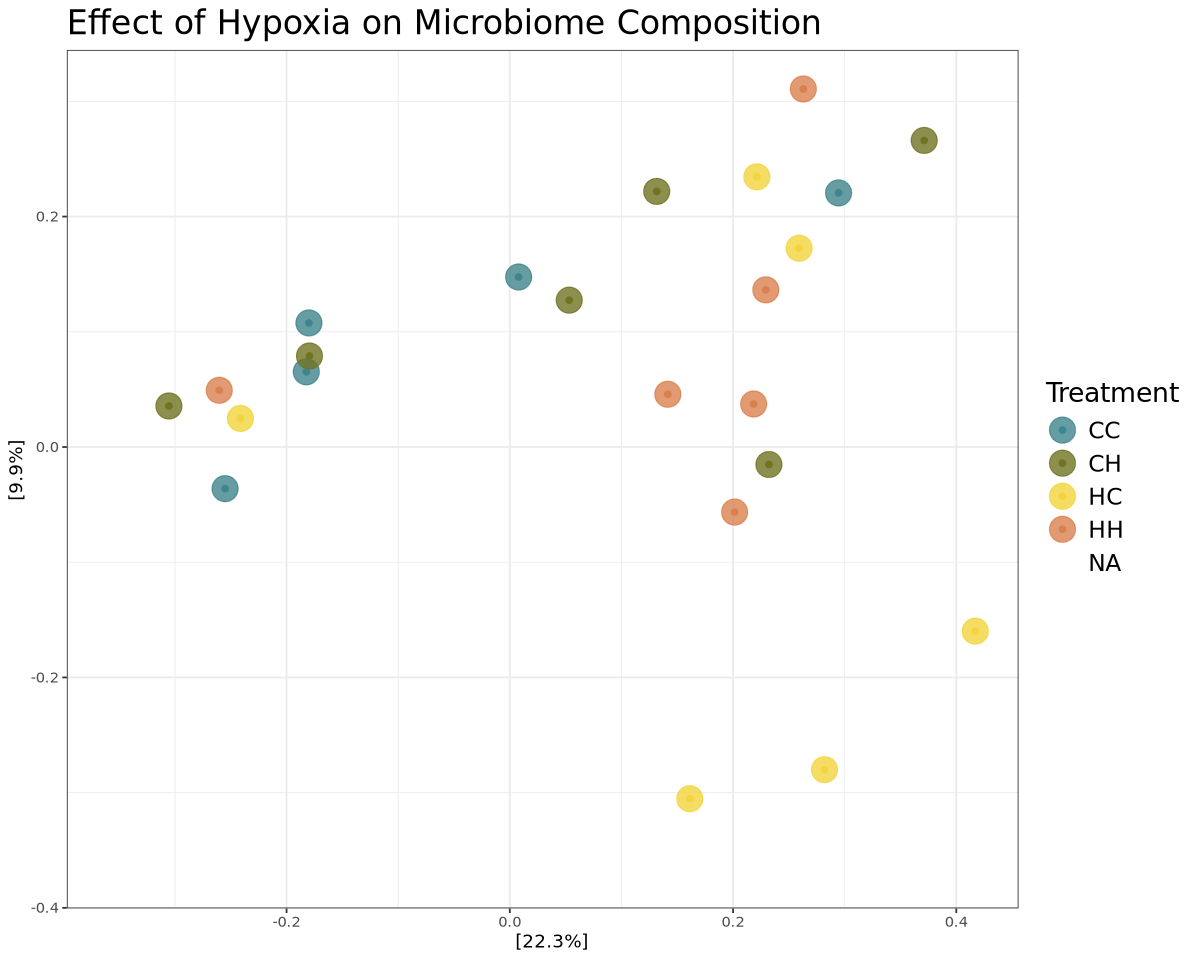

In [158]:
plot_ordination(ps_hyp2_gill, ordu_gill, color="Combined_treat") +
    geom_point(size=7, alpha=0.8) +
    labs(title="Effect of Hypoxia on Microbiome Composition", color="Treatment") +
    scale_colour_paletteer_d("vangogh::Chaise")+
    theme_bw() +
    theme(plot.title=element_text(size=20), legend.title=element_text(size=16), legend.text=element_text(size=14))
    

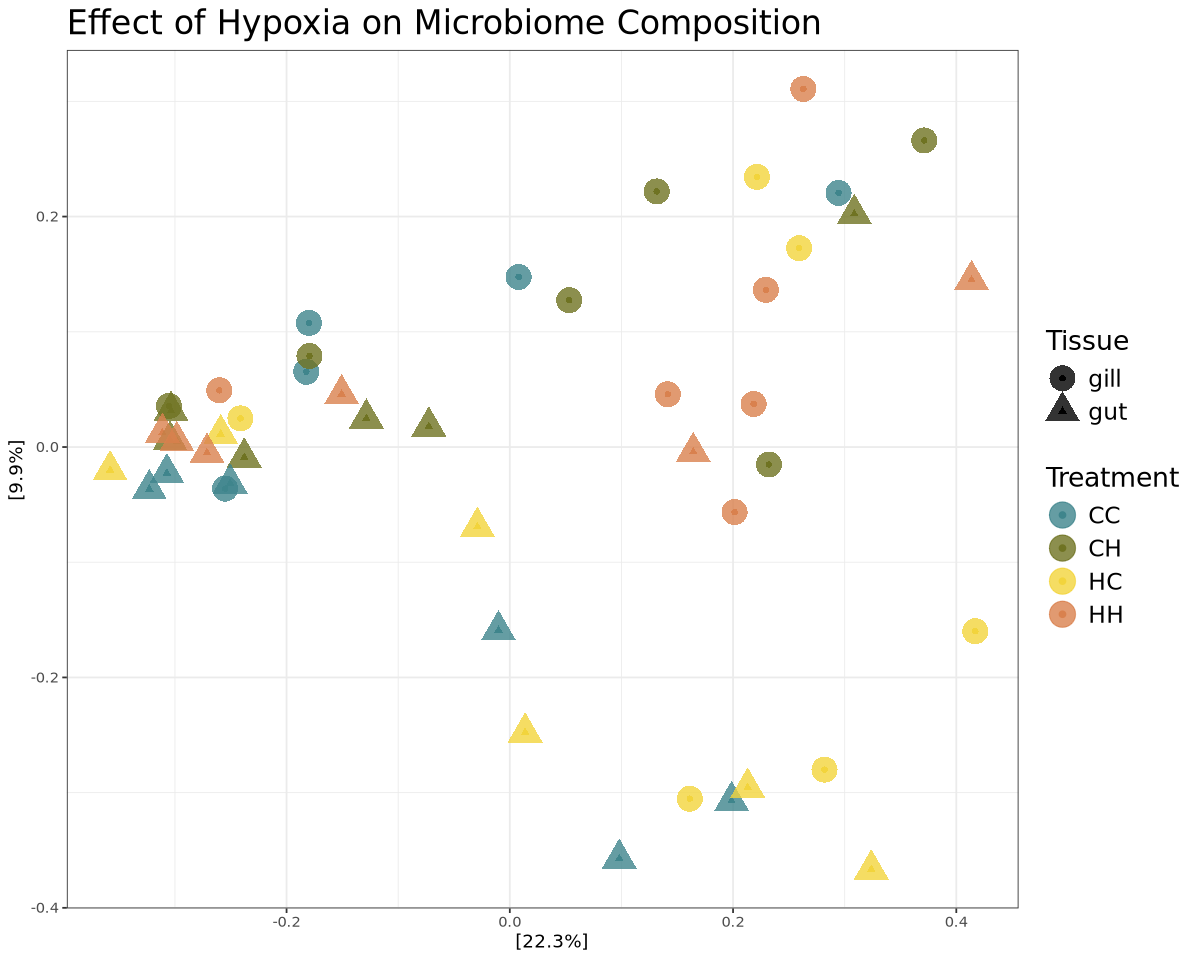

In [151]:
options(repr.plot.width=10, repr.plot.height=8)
plot_ordination(ps_hyp2, ordu, color="Combined_treat", shape="Tissue") +
    geom_point(size=7, alpha=0.8) +
    labs(title="Effect of Hypoxia on Microbiome Composition", color="Treatment") +
    scale_colour_paletteer_d("vangogh::Chaise")+
    theme_bw() +
    theme(plot.title=element_text(size=20), legend.title=element_text(size=16), legend.text=element_text(size=14))
    

In [125]:
# Aggregate taxa at the family level
ps_phyla <- tax_glom(ps_hyp2, taxrank = "phylum")

In [126]:

# List of the top 50 most abundant families
top10phyla <- names(sort(taxa_sums(ps_phyla), decreasing=TRUE))[1:10]

# Only include those families in the phyloseq object
ps_phyla <- prune_taxa(top10phyla, ps_phyla)

In [127]:
library(paletteer)

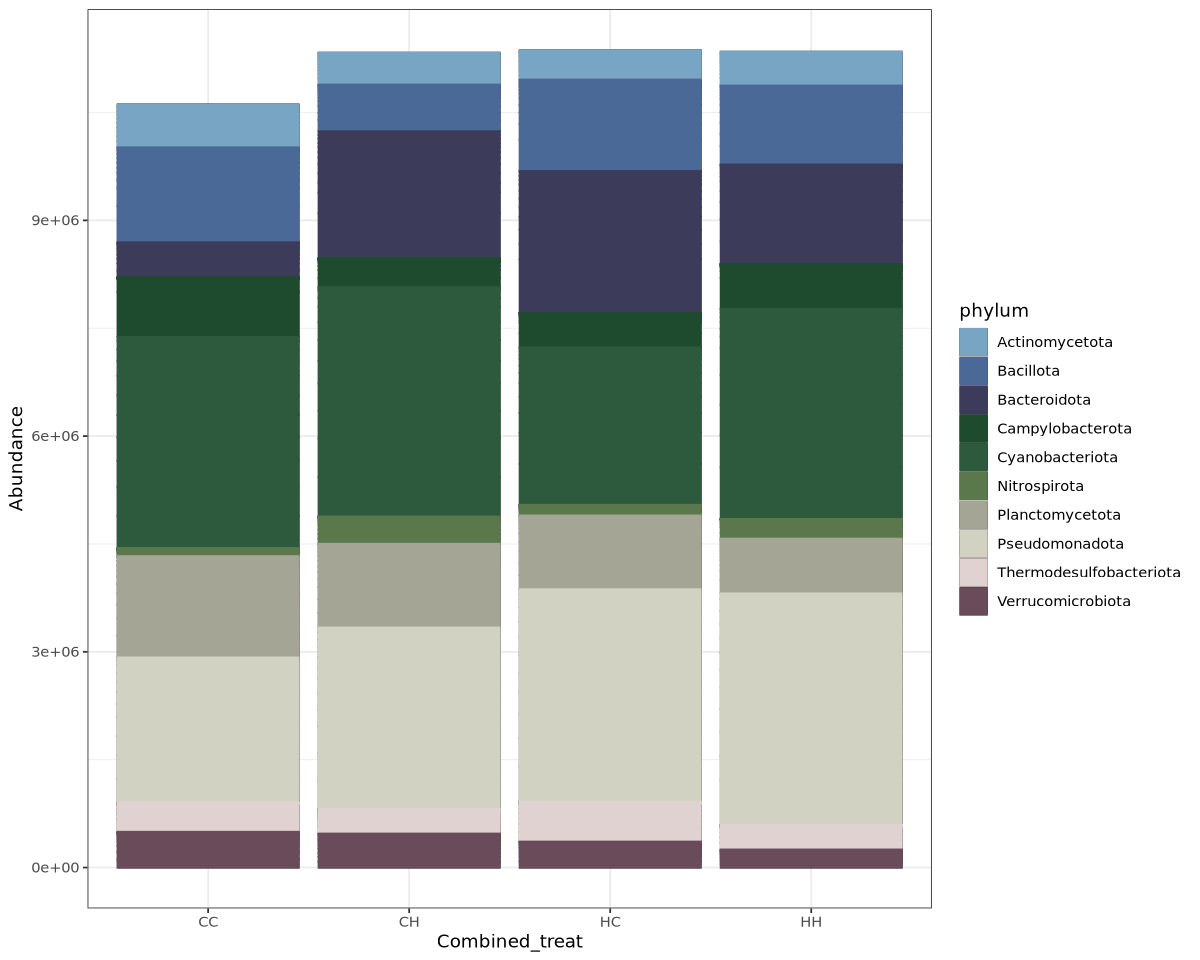

In [128]:
plot_bar(ps_phyla, x = "Combined_treat", fill = "phylum") +
    geom_bar(aes(color=phylum, fill=phylum), stat="identity", position="stack") +
    scale_colour_paletteer_d("impressionist.colors::fleurs_dans_un_vase_de_cristal") +
    scale_fill_paletteer_d("impressionist.colors::fleurs_dans_un_vase_de_cristal") +
    theme_bw()

In [129]:
# Aggregate taxa at the family level
ps_order <- tax_glom(ps_hyp2, taxrank = "order")

# List of the top 50 most abundant families
top10order <- names(sort(taxa_sums(ps_order), decreasing=TRUE))[1:10]

# Only include those families in the phyloseq object
ps_order <- prune_taxa(top10order, ps_order)

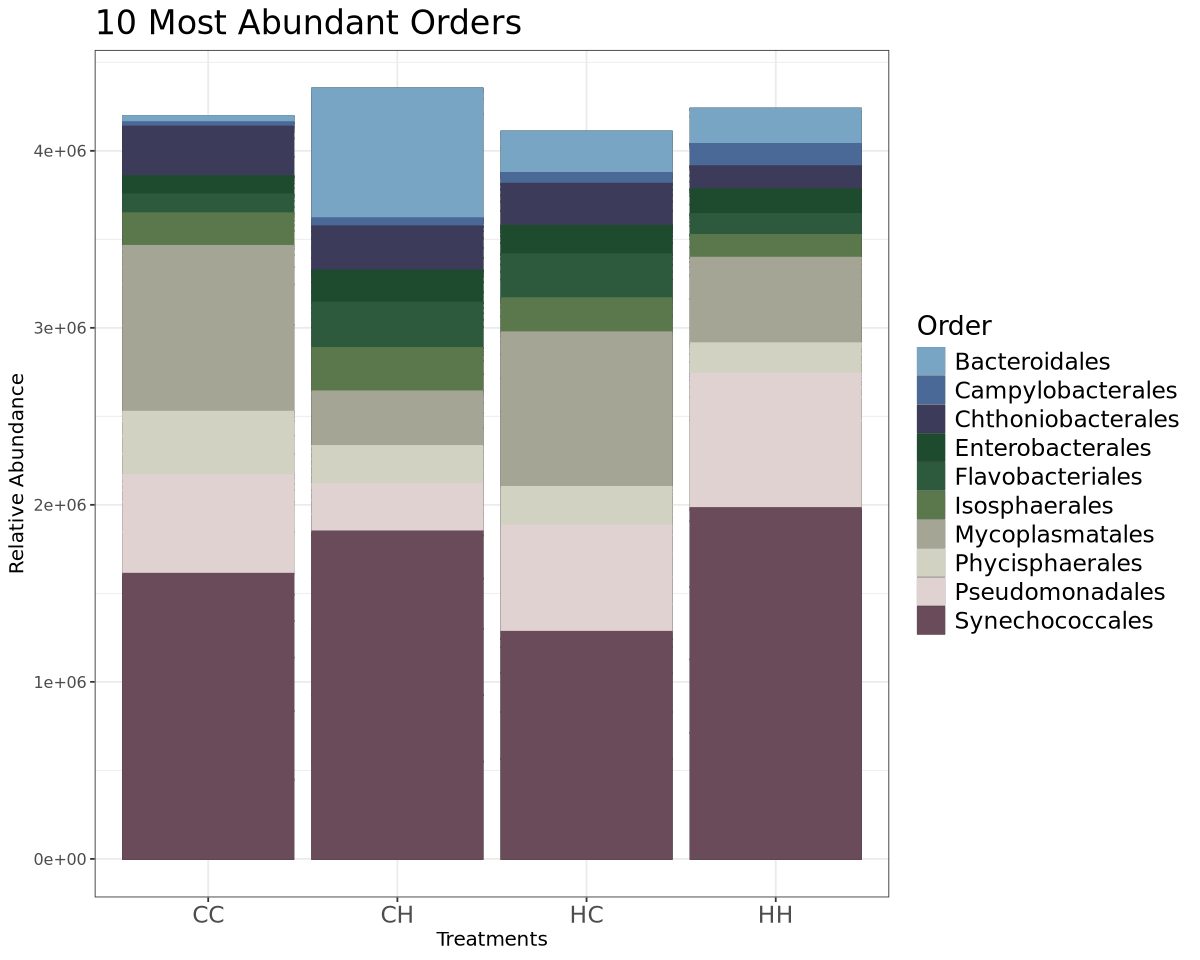

In [153]:
ps_gut <- subset_samples(ps_order, Tissue == "gut")

plot_bar(ps_gut, x = "Combined_treat", fill = "order") +
    geom_bar(aes(color=order, fill=order), stat="identity", position="stack") +
    scale_colour_paletteer_d("impressionist.colors::fleurs_dans_un_vase_de_cristal") +
    scale_fill_paletteer_d("impressionist.colors::fleurs_dans_un_vase_de_cristal") +
    labs(title="10 Most Abundant Orders", color="Order", fill="Order", y="Relative Abundance", x="Treatments") +
    theme_bw() +
    theme(plot.title=element_text(size=20), legend.title=element_text(size=16), legend.text=element_text(size=14), axis.text.x=element_text(size=14), text=element_text(size = 12))

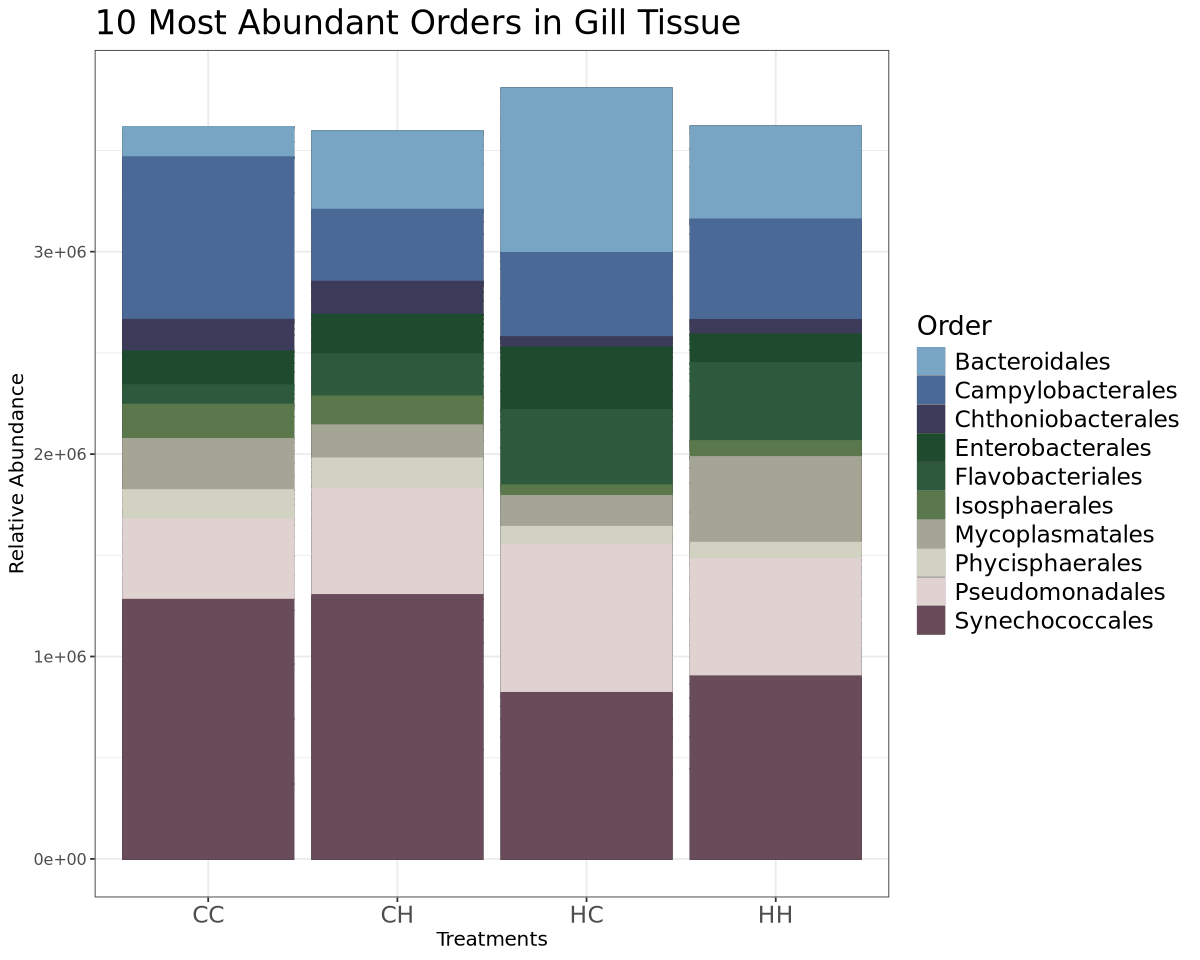

In [154]:
ps_gill <- subset_samples(ps_order, Tissue == "gill")

plot_bar(ps_gill, x = "Combined_treat", fill = "order") +
    geom_bar(aes(color=order, fill=order), stat="identity", position="stack") +
    scale_colour_paletteer_d("impressionist.colors::fleurs_dans_un_vase_de_cristal") +
    scale_fill_paletteer_d("impressionist.colors::fleurs_dans_un_vase_de_cristal") +
    labs(title="10 Most Abundant Orders in Gill Tissue", color="Order", fill="Order", y="Relative Abundance", x="Treatments") +
    theme_bw() +
    theme(plot.title=element_text(size=20), legend.title=element_text(size=16), legend.text=element_text(size=14), axis.text.x=element_text(size=14), text=element_text(size = 12))

In [132]:
# Aggregate taxa at the family level
ps_fam <- tax_glom(ps_hyp2, taxrank = "family")

# List of the top 50 most abundant families
top10fam <- names(sort(taxa_sums(ps_fam), decreasing=TRUE))[1:10]

# Only include those families in the phyloseq object
ps_fam <- prune_taxa(top10fam, ps_fam)

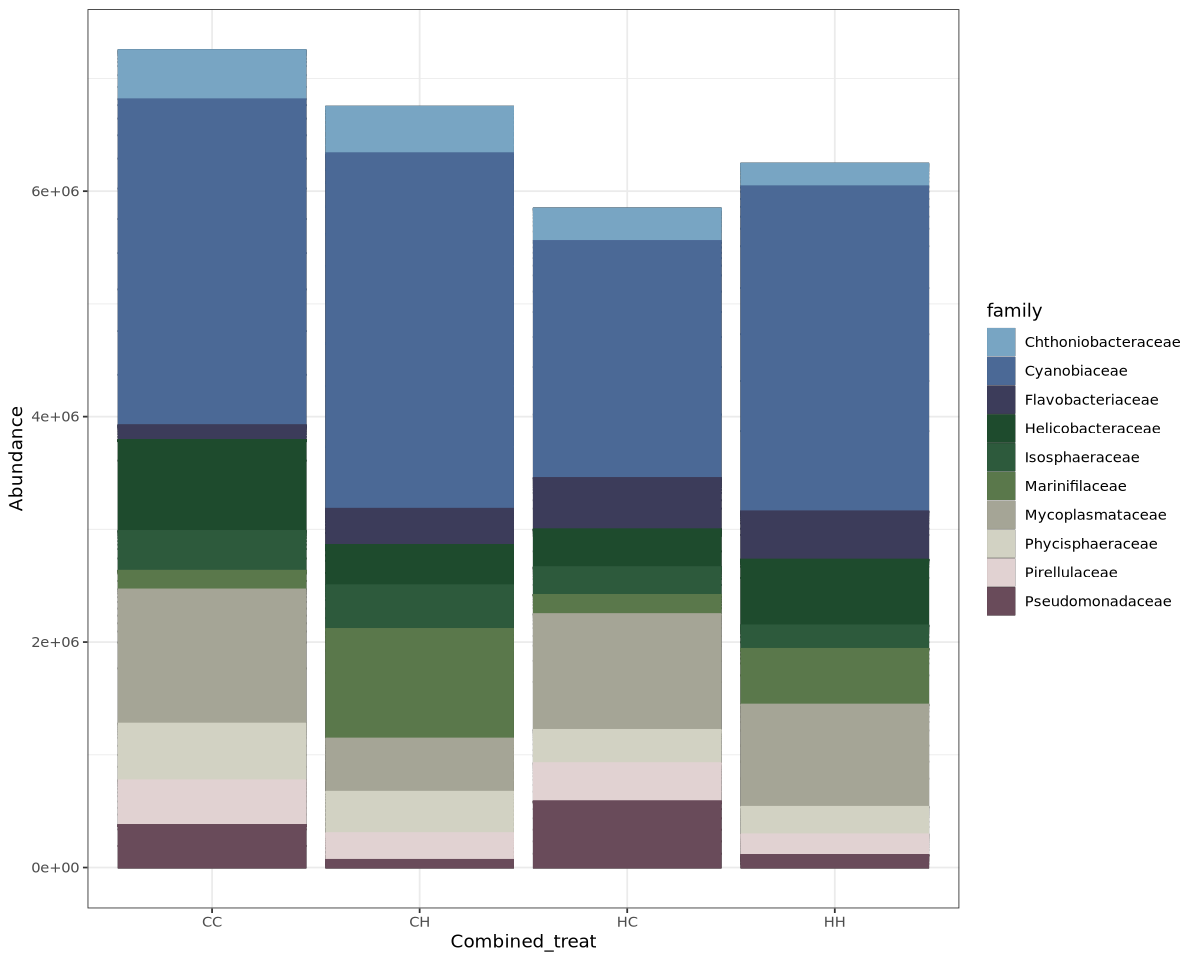

In [135]:
plot_bar(ps_fam, x = "Combined_treat", fill = "family") +
    geom_bar(aes(color=family, fill=family), stat="identity", position="stack") +
    scale_colour_paletteer_d("impressionist.colors::fleurs_dans_un_vase_de_cristal") +
    scale_fill_paletteer_d("impressionist.colors::fleurs_dans_un_vase_de_cristal") +
    theme_bw()

### Look at phylum level diversity

In [ ]:
# Create table, number of features for each phyla
phylumPrev <- apply(X = otu_table(ps_prune),
                 MARGIN = ifelse(taxa_are_rows(ps_prune), yes = 1, no = 2),
                 FUN = function(x){sum(x > 0)})
phylumPrev <- data.frame(Prevalence = phylumPrev,
                      TotalAbundance = taxa_sums(ps_prune),
                      tax_table(ps_prune))

# Total and average phylum prev
plyr::ddply(phylumPrev, "phylum", function(df2){
  cbind(Average_Prevalence = mean(df2$Prevalence), 
        Total_Prevalence = sum(df2$Prevalence))
})

### Bar plot

In [ ]:
# Aggregate taxa at the family level
ps_fam <- tax_glom(ps_norm, taxrank = "family")

# List of the top 50 most abundant families
top50 <- names(sort(taxa_sums(ps_fam), decreasing=TRUE))[1:50]

# Only include those families in the phyloseq object
ps_fam_50 <- prune_taxa(top50, ps_fam)

In [72]:
sum(is.na(otu_table(ps_fam_50)))

[1] 0

In [78]:
# Remove samples with missing Tissue
ps_noNA <- subset_samples(ps_fam_50, !is.na(Tissue))

# Remove taxa with missing Family
ps_noNA <- subset_taxa(ps_noNA, !is.na(family))

In [90]:
library(RColorBrewer)

In [92]:
#assigning colors
famcolors= colorRampPalette(brewer.pal(8, "Accent"))(50)

#Generate a random set of colors based on a df fam_taxa that assigns a random color to each spot in the list
fam_taxa <- unique(tax_table(ps_fam_50)[, "family"])
    famcolors <- sample(famcolors, 50, length(fam_taxa))
    # naming my color palette so the random order stays the same
    famcolors<- setNames(famcolors, fam_taxa)

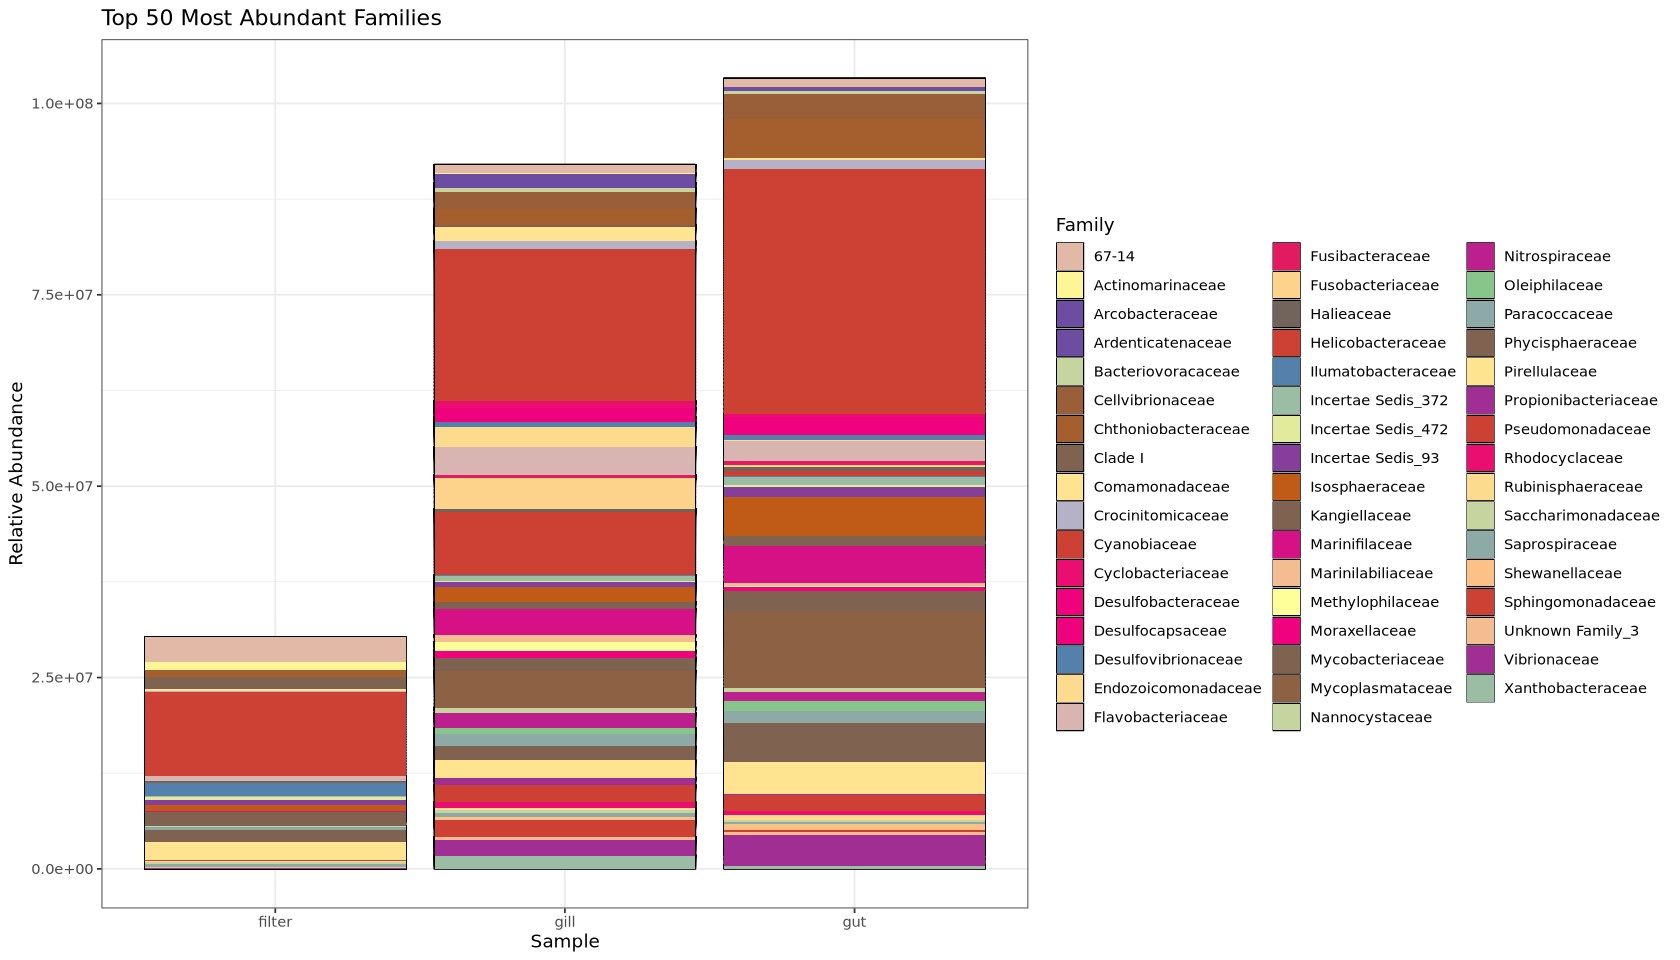

In [95]:
plot_bar(ps_noNA, x = "Tissue", fill = "family") +
  geom_bar(aes(fill=family), stat = "identity", position = "stack") +
  scale_fill_manual(values = famcolors) +
  theme_bw() +
  labs(
    x = "Sample",
    y = "Relative Abundance",
    fill = "Family",
    title = "Top 50 Most Abundant Families"
  )



plot_richness(ps, x="Combined_treat", measures=c("Shannon", "Simpson"), color="Phase")

In [74]:
ps.prop <- transform_sample_counts(ps_sub, function(otu) otu/sum(otu))
ord.nmds.bray <- ordinate(ps.prop, method="NMDS", distance="bray")

Run 0 stress 0.1538333 
Run 1 stress 0.1552541 
Run 2 stress 0.1896792 
Run 3 stress 0.1555948 
Run 4 stress 0.1555948 
Run 5 stress 0.1552541 
Run 6 stress 0.1535124 
... New best solution
... Procrustes: rmse 0.01043438  max resid 0.073201 
Run 7 stress 0.1646217 
Run 8 stress 0.1556833 
Run 9 stress 0.1552541 
Run 10 stress 0.1677257 
Run 11 stress 0.1638807 
Run 12 stress 0.1606776 
Run 13 stress 0.1627264 
Run 14 stress 0.1535124 
... New best solution
... Procrustes: rmse 2.048658e-05  max resid 0.0001009637 
... Similar to previous best
Run 15 stress 0.1555949 
Run 16 stress 0.1552541 
Run 17 stress 0.1603381 
Run 18 stress 0.1552541 
Run 19 stress 0.1829705 
Run 20 stress 0.1638781 
*** Best solution repeated 1 times


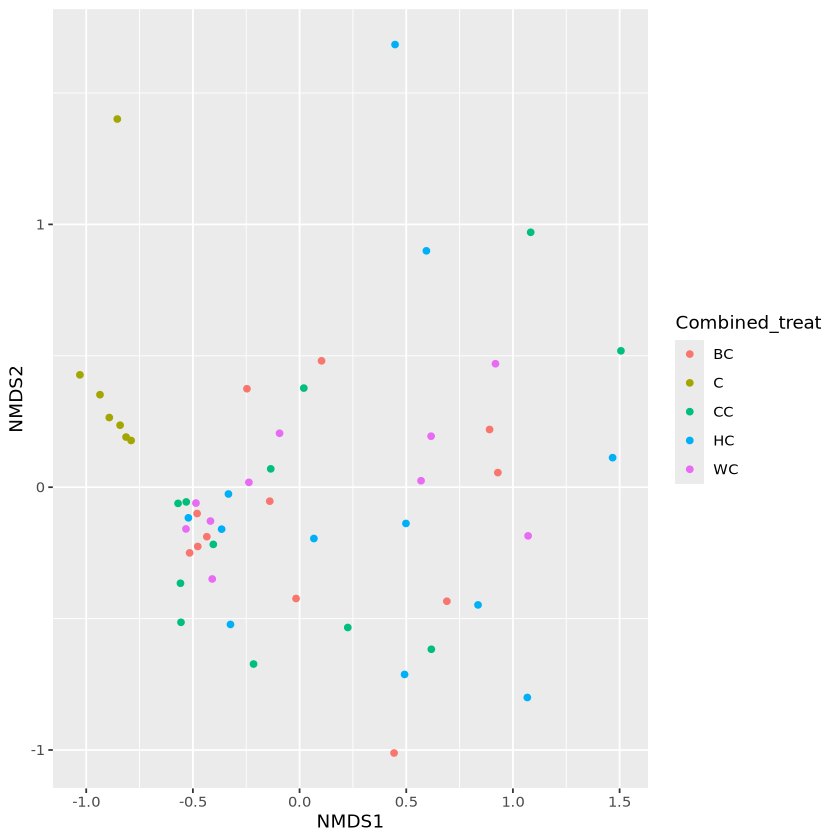

In [76]:
plot_ordination(ps.prop, ord.nmds.bray, type="samples", color="Combined_treat" )

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 34583 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 34583 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 34583 reference sequences ]

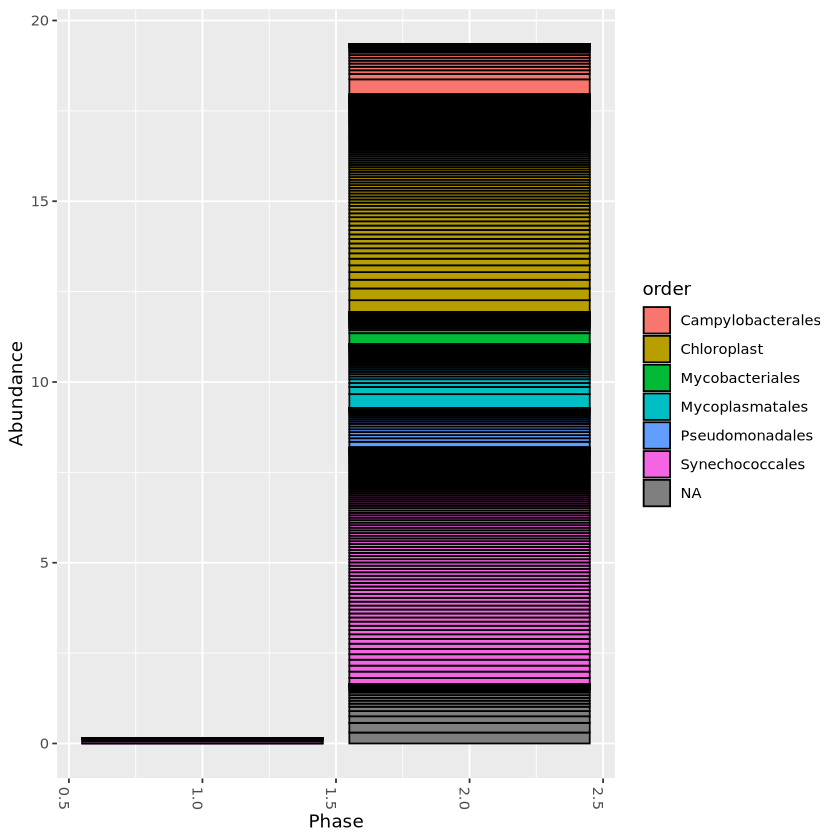

In [79]:
top20 <- names(sort(taxa_sums(ps_sub), decreasing=TRUE))[1:10]
ps.top20 <- transform_sample_counts(ps_sub, function(OTU) OTU/sum(OTU))
ps.top20 <- prune_taxa(top20, ps.top20)
plot_bar(ps.top20, x="Phase", fill="order")

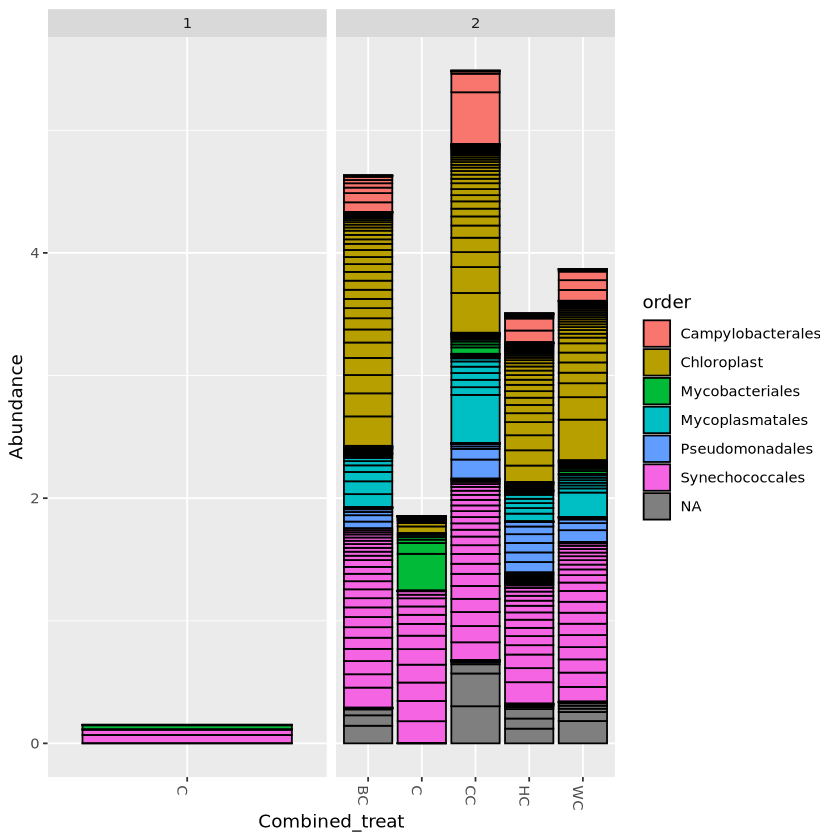

In [73]:
top20 <- names(sort(taxa_sums(ps_sub), decreasing=TRUE))[1:10]
ps.top20 <- transform_sample_counts(ps_sub, function(OTU) OTU/sum(OTU))
ps.top20 <- prune_taxa(top20, ps.top20)
plot_bar(ps.top20, x="Combined_treat", fill="order") + facet_wrap(~Phase, scales="free_x")

In [43]:
tax <- as(tax_table(ps), "matrix")

# Function to calculate classification rate
classification_rate <- function(x) {
  classified <- !is.na(x) &
    trimws(x) != "" &
    !grepl("unclassified|unknown|uncultured|unassigned",
           x, ignore.case = TRUE)

  mean(classified) * 100
}

# Calculate rate for each taxonomic rank
rates <- apply(tax, 2, classification_rate)

round(rates, 2)

domain  phylum   class   order  family   genus species 
  46.63   37.24   35.58   28.47   24.97   18.26    0.00

In [45]:
tax <- as(tax_table(ps_bac), "matrix")

# Function to calculate classification rate
classification_rate <- function(x) {
  classified <- !is.na(x) &
    trimws(x) != "" &
    !grepl("unclassified|unknown|uncultured|unassigned",
           x, ignore.case = TRUE)

  mean(classified) * 100
}

# Calculate rate for each taxonomic rank
rates <- apply(tax, 2, classification_rate)

round(rates, 2)

domain  phylum   class   order  family   genus species 
 100.00   79.58   75.97   60.54   53.06   38.67    0.00